# Project: Variable renewable energy

[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/mec557/ml4climate/master?urlpath=%2Fdoc%2Ftree%2Fml4climate%2Fnotebooks%2Fproject_vre.ipynb)

***Projet réalisé par: Alexis Capenter, Christian Fahe***

<div class="alert alert-block alert-warning">
    <b>Schedule</b>
    
- Ask your supervisors for the data if not already provided (it is not included in this repository).
- Quick presentation.
- Final project presentation.
    
</div>

<div class="alert alert-block alert-info">
    <b>One problematic, One dataset, One (or more) method(s)</b>
    
- Quality of the dataset is key.
- Results on a clean notebook.
- Explain which method(s) you used and why.
- If a method fails, explain why.

</div>

## Variable Renewable Energy (VRE) assessment and forecast

### Project objectives
<div class="alert alert-block alert-info">

- Assess the solar photovoltaic hourly production over in metropolitan France regions using climate data and capacity factor observations.
- Predict the VRE power ahead of time.
</div>

 1. We will use solar power
 2. Read solar productin=on assesment and forecast
 3. Estimate the hourly solar production

### Reading the data

In [13]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr

# Directories where you saved the data
data_dir_energy = Path('C:/Projet-VRE/data')
data_dir_climate = Path('C:/Projet-VRE/data/climate_france')

# Template filenames
filename_mask = 'mask_datagouv_french_regions_merra2_Nx_France.nc'
filename_climate = 'merra2_area_selection_output_{}_merra2_2010-2019.nc'
filename_energy = 'reseaux_energies_{}.csv'


Text(0, 0.5, 'Facteur de charge (-)')

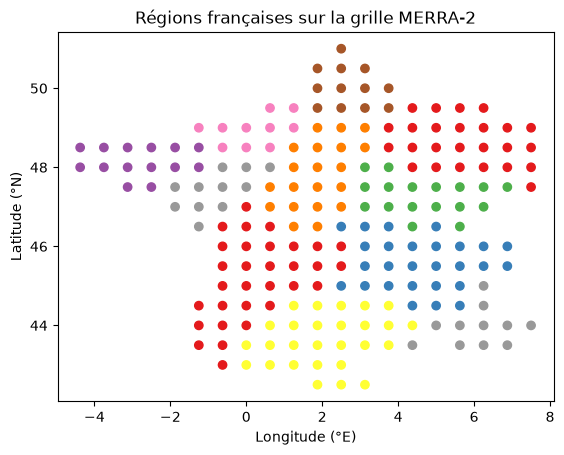

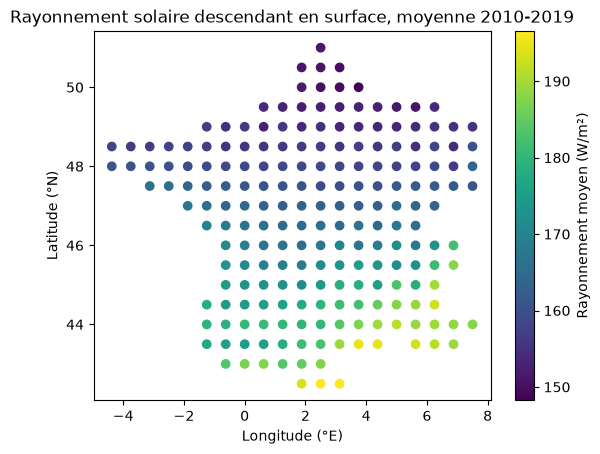

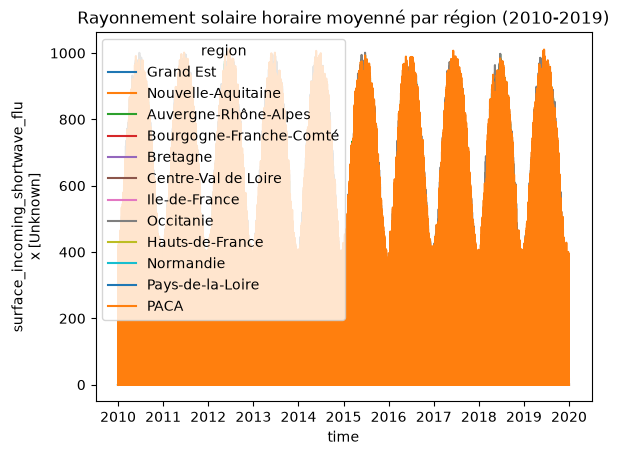

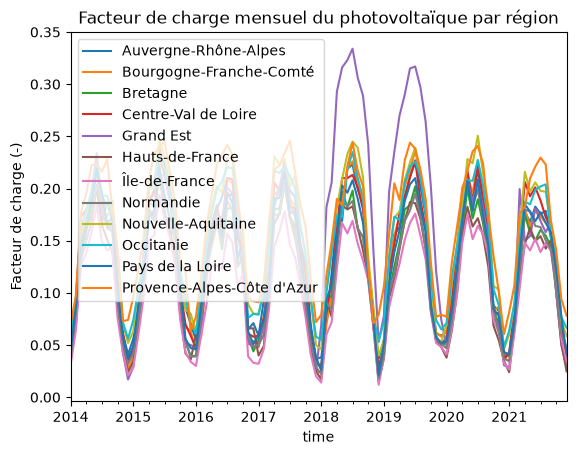

In [24]:
# Read and plot grid point-region mask
filepath_mask = Path(data_dir_climate, filename_mask)
ds_mask = xr.load_dataset(filepath_mask)
da_mask = ds_mask['mask']
plt.figure()
plt.scatter(da_mask['lon'], da_mask['lat'], c=da_mask, cmap='Set1')
plt.title('Régions françaises sur la grille MERRA-2')
plt.xlabel('Longitude (°E)')
plt.ylabel('Latitude (°N)')

# Read a climate variable and plot its mean over time
variable_name = 'surface_downward_radiation'
filename = filename_climate.format(variable_name)
filepath = Path(data_dir_climate, filename)
da_climate = xr.load_dataset(filepath)[variable_name]
plt.figure()
plt.scatter(da_mask['lon'], da_mask['lat'], c=da_climate.mean('time'))
plt.colorbar(label='Rayonnement moyen (W/m²)')
plt.title('Rayonnement solaire descendant en surface, moyenne 2010-2019')
plt.xlabel('Longitude (°E)')
plt.ylabel('Latitude (°N)')

# Compute regional mean of climate variable and plot time series
da_climate_reg = da_climate.groupby(da_mask).mean().rename(mask='region')
da_climate_reg['region'] = ds_mask['region'].values
plt.figure()
da_climate_reg.plot.line(x='time')
plt.title('Rayonnement solaire horaire moyenné par région (2010-2019)')

# Read energy variable and plot time series
variable_name = 'capacityfactor_pv'
filename = filename_energy.format(variable_name)
filepath = Path(data_dir_energy, filename)
df_energy = pd.read_csv(filepath, index_col=0, header=0, parse_dates=True)
ax = df_energy.plot(title='Facteur de charge mensuel du photovoltaïque par région')
ax.set_ylabel('Facteur de charge (-)')

# compute the energy demand
#variable_name = 'demand_demand'
#filename = filename_energy.format(variable_name)
#filepath = Path(data_dir_energy, filename)
#df_en_dem = pd.read_csv(filepath, index_col=0, header=0, parse_dates=True)
#ax = df_en_dem.plot(title="demande d'énergie par région")


**Facteur de charge**: Le facteur de charge d'une installation photovoltaïque est le rapport entre l'énergie réellement produite sur une période donnée (par exemple un an) et l'énergie qu'elle aurait produite si elle avait fonctionné en continu à sa puissance nominale (puissance crête)

$\text{Facteur de charge(\%)} = \frac{\text{Energie produite sur la période(kWh)}}{\text{Puissance nominale(kW)} \times \text{nombres d'heures de la période}} \times 100$



,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Grand Est,Hauts-de-France,Île-de-France,Normandie,Nouvelle-Aquitaine,Occitanie,Pays de la Loire,Provence-Alpes-Côte d'Azur
time,,,,,,,,,,,,
2014-01-01,0.0510,0.0480,0.0450,0.0480,0.0440,0.0350,0.0310,0.0380,0.0530,0.0570,0.0440,0.0700
2014-02-01,0.0790,0.0780,0.0810,0.0920,0.0680,0.0680,0.0640,0.0810,0.0880,0.0960,0.0860,0.0970
2014-03-01,0.1560,0.1610,0.1340,0.1730,0.1560,0.1410,0.1270,0.1320,0.1540,0.1620,0.1470,0.1770
2014-04-01,0.1740,0.1790,0.1590,0.1800,0.1690,0.1630,0.1380,0.1500,0.1740,0.1790,0.1670,0.1950
2014-05-01,0.1870,0.1950,0.1840,0.1940,0.1930,0.1740,0.1580,0.1680,0.1890,0.1980,0.1870,0.2220
...,...,...,...,...,...,...,...,...,...,...,...,...
2021-08-01,0.1786,0.1671,0.1548,0.1725,0.1581,0.1424,0.1482,0.1502,0.1970,0.2040,0.1671,0.2230
2021-09-01,0.1520,0.1630,0.1444,0.1625,0.1682,0.1508,0.1400,0.1418,0.1640,0.1534,0.1578,0.1689
2021-10-01,0.1210,0.1242,0.1143,0.1316,0.1010,0.1007,0.1056,0.1017,0.1362,0.1341,0.1226,0.1413


In [28]:
da_mask

<xarray.DataArray 'mask' (stacked_dim: 205)> Size: 2kB
array([ 9,  9,  9,  3,  9,  9,  9,  9,  9,  3,  3,  9,  9,  9,  9,  9,  9,
        9, 13, 13, 13, 13,  3,  3,  3,  9,  9,  9,  9,  9,  9,  9, 13, 13,
       13, 13, 13,  3,  3,  3,  3,  9,  9,  9,  9,  9,  4,  4,  4, 13,  3,
        3,  3,  3,  3,  4,  4,  4,  4,  4,  4, 13,  3,  3,  3,  3,  3,  3,
        4,  4,  4,  4,  4,  4,  4,  3,  3,  3,  3,  3,  3,  4,  4,  4,  4,
        4,  4,  4, 12,  3,  3,  3,  7,  7,  4,  4,  4,  5,  4,  5, 12, 12,
       12,  3,  7,  7,  7,  7,  5,  5,  5,  5,  5,  5,  6,  6, 12, 12, 12,
       12,  7,  7,  7,  7,  5,  5,  5,  5,  5,  5,  5,  2,  6,  6,  6,  6,
        6,  6, 12, 12, 12,  7,  7,  7,  5,  5,  2,  2,  2,  2,  2,  2,  6,
        6,  6,  6,  6,  6, 11, 11, 11,  7,  8,  8,  8,  2,  2,  2,  2,  2,
        2,  2, 11, 11, 11, 11, 11,  8,  8,  8,  2,  2,  2,  2,  2,  2,  2,
       11, 11, 10, 10, 10, 10,  2,  2,  2,  2, 10, 10, 10, 10, 10, 10, 10,
       10])
Coordinates:
    lat      (stacked_dim) float64 2kB 42.5 42.5 42.5 43.0 ... 50.5 50.5 51.0
    lon      (stacked_dim) float64 2kB 1.875 2.5 3.125 -0.625 ... 2.5 3.125 2.5
Dimensions without coordinates: stacked_dim

In [29]:
da_climate

<xarray.DataArray 'surface_downward_radiation' (time: 87648, stacked_dim: 205)> Size: 72MB
array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(87648, 205), dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 701kB 2010-01-01 ... 2019-12-31T23:00:00
    lat      (stacked_dim) float64 2kB 42.5 42.5 42.5 43.0 ... 50.5 50.5 51.0
    lon      (stacked_dim) float64 2kB 1.875 2.5 3.125 -0.625 ... 2.5 3.125 2.5
Dimensions without coordinates: stacked_dim
Attributes:
    long_name:       surface_incoming_shortwave_flux
    units:           Unknown
    fmissing_value:  1e+15
    standard_name:   surface_incoming_shortwave_flux
    vmax:            1e+15
    vmin:            -1e+15
    valid_range:     [-1.e+15  1.e+15]
    origname:        SWGDN
    fullnamepath:    /SWGDN
    height:          2.0

J'ai 205 points sur la carte. Chaque point a:
- long
- lat
- une region
- une séries temporelle


Chaque region a chaque mois *un facteur de charge*

> Est-ce que la prediction qu'on veut est une prédiction par point ou par région?

***
## Credit

[//]: # "This notebook is part of [E4C Interdisciplinary Center - Education](https://gitlab.in2p3.fr/energy4climate/public/education)."
Contributors include Bruno Deremble and Alexis Tantet.
Several slides and images are taken from the very good [Scikit-learn course](https://inria.github.io/scikit-learn-mooc/).

<br>

<div style="display: flex; height: 70px">
    
<img alt="Logo LMD" src="images/logos/logo_lmd.jpg" style="display: inline-block"/>

<img alt="Logo IPSL" src="images/logos/logo_ipsl.png" style="display: inline-block"/>

<img alt="Logo E4C" src="images/logos/logo_e4c_final.png" style="display: inline-block"/>

<img alt="Logo EP" src="images/logos/logo_ep.png" style="display: inline-block"/>

<img alt="Logo SU" src="images/logos/logo_su.png" style="display: inline-block"/>

<img alt="Logo ENS" src="images/logos/logo_ens.jpg" style="display: inline-block"/>

<img alt="Logo CNRS" src="images/logos/logo_cnrs.png" style="display: inline-block"/>
    
</div>

<hr>

<div style="display: flex">
    <a rel="license" href="http://creativecommons.org/licenses/by-sa/4.0/"><img alt="Creative Commons License" style="border-width:0; margin-right: 10px" src="https://i.creativecommons.org/l/by-sa/4.0/88x31.png" /></a>
    <br>This work is licensed under a &nbsp; <a rel="license" href="http://creativecommons.org/licenses/by-sa/4.0/">Creative Commons Attribution-ShareAlike 4.0 International License</a>.
</div>